# Hospital Patient Data Analysis - SQLite

This notebook loads hospital records from a SQLite database in read-only mode, validates and cleans them, saves cleaned copies, and explores costs, demographics, and length of stay. This version targets SQLite; server databases such as MySQL/PostgreSQL require separate connection configuration.

In [ ]:
from contextlib import closing
from datetime import datetime
from pathlib import Path
import sqlite3

import matplotlib.pyplot as plt
import pandas as pd

%matplotlib inline

PROJECT_DIR = Path.cwd()
SQLITE_DB_PATH = PROJECT_DIR / 'data' / 'hospital.db'
SQL_TABLE_NAME = 'hospital'
# Optional: provide a SELECT statement to load a filtered result instead.
SQL_QUERY = None
REQUIRED_COLUMNS = {
    'Patient_ID', 'Age', 'Gender', 'Condition', 'Admission_Date',
    'Discharge_Date', 'Patient_State', 'Year_of_Admission',
    'Length_of_Stay', 'Readmission', 'Outcome', 'Satisfaction',
    'Insurance_Claimed', 'Total_Cost'
}


If `data/hospital.db` does not exist yet, create it once from the project CSV using this setup cell. This is a separate, explicit import step; the analysis connection below remains read-only.

In [2]:
CSV_PATH = PROJECT_DIR / 'data' / 'raw' / 'hospital_original.csv'
if not SQLITE_DB_PATH.exists():
    if not CSV_PATH.exists():
        raise FileNotFoundError(f'Neither SQLite database nor setup CSV exists: {SQLITE_DB_PATH}, {CSV_PATH}')
    records = pd.read_csv(CSV_PATH)
    SQLITE_DB_PATH.parent.mkdir(parents=True, exist_ok=True)
    with closing(sqlite3.connect(SQLITE_DB_PATH)) as connection:
        records.to_sql(SQL_TABLE_NAME, connection, if_exists='fail', index=False)
    print(f'Created SQLite database and table: {SQLITE_DB_PATH} ({SQL_TABLE_NAME})')
else:
    print(f'Using existing SQLite database: {SQLITE_DB_PATH}')


Using existing SQLite database: c:\Users\Lenovo\Desktop\UPJ_Prog\Python\VAP_2\data\hospital.db


In [3]:
if not SQLITE_DB_PATH.exists():
    raise FileNotFoundError(f'SQLite database not found: {SQLITE_DB_PATH}')
if SQL_QUERY is None:
    quoted_table = '"' + SQL_TABLE_NAME.replace('"', '""') + '"'
    query = f'SELECT * FROM {quoted_table}'
else:
    query = SQL_QUERY

database_uri = f'{SQLITE_DB_PATH.resolve().as_uri()}?mode=ro'
with closing(sqlite3.connect(database_uri, uri=True)) as connection:
    df = pd.read_sql_query(query, connection)

df.columns = df.columns.astype(str).str.strip()
missing_columns = REQUIRED_COLUMNS - set(df.columns)
if missing_columns:
    raise ValueError(f'Missing required columns: {sorted(missing_columns)}')

print(f'Loaded {len(df)} rows from SQLite table {SQL_TABLE_NAME!r}.')
df.head()


Loaded 984 rows from SQLite table 'hospital'.


,Patient_ID,Age,Gender,Condition,Medication,Admission_Date,Discharge_Date,Patient_State,Year_of_Admission,Length_of_Stay,Readmission,Outcome,Satisfaction,Insurance_Claimed,Total_Cost
0,1,45,Female,Heart Disease,None,07-02-2024,12-02-2024,Kerala,2024,5,No,Recovered,4,Yes,15000
1,2,60,Male,Diabetes,None,11-03-2023,14-03-2023,Goa,2023,3,Yes,Stable,3,No,2000
2,3,32,Female,Fractured Arm,None,02-01-2025,03-01-2025,Maharastra,2025,1,No,Recovered,5,Yes,500
3,4,75,Male,Stroke,None,30-12-2023,06-01-2024,Manipur,2023,7,Yes,Stable,2,No,10000
4,5,50,Female,Cancer,None,10-05-2022,20-05-2022,Mizoram,2022,10,No,Recovered,4,No,25000


In [4]:
for column in ['Age', 'Year_of_Admission', 'Length_of_Stay', 'Satisfaction', 'Total_Cost']:
    df[column] = pd.to_numeric(df[column], errors='coerce')

for column in ['Admission_Date', 'Discharge_Date']:
    df[column] = pd.to_datetime(df[column], dayfirst=True, errors='coerce')

for column in ['Readmission', 'Insurance_Claimed']:
    df[column] = df[column].astype('string').str.strip().str.capitalize()

if df['Patient_ID'].duplicated().any():
    print('Warning: duplicate Patient_ID values found.')
if (df['Age'] < 0).any():
    print('Warning: negative age values found.')
if (df['Total_Cost'] < 0).any():
    print('Warning: negative cost values found.')

invalid_stay = df['Discharge_Date'] < df['Admission_Date']
if invalid_stay.any():
    print(f'Warning: {invalid_stay.sum()} discharge date(s) precede admission.')

cleaned_path = PROJECT_DIR / 'data' / 'cleaned' / 'hospital_cleaned_sql.csv'
cleaned_path.parent.mkdir(parents=True, exist_ok=True)
df.to_csv(cleaned_path, index=False)
backup_path = PROJECT_DIR / 'data' / 'backups' / f'hospital_sql_{datetime.now():%Y-%m-%d}.csv'
backup_path.parent.mkdir(parents=True, exist_ok=True)
df.to_csv(backup_path, index=False)
print(f'Cleaned data saved to: {cleaned_path}')
print(f'Daily backup saved to: {backup_path}')
print('Missing values per column:\n', df.isna().sum())


Cleaned data saved to: c:\Users\Lenovo\Desktop\UPJ_Prog\Python\VAP_2\data\cleaned\hospital_cleaned_sql.csv
Daily backup saved to: c:\Users\Lenovo\Desktop\UPJ_Prog\Python\VAP_2\data\backups\hospital_sql_2026-10-05.csv
Missing values per column:
 Patient_ID             0
Age                    0
Gender                 0
Condition              0
Medication           984
Admission_Date         0
Discharge_Date         0
Patient_State          0
Year_of_Admission      0
Length_of_Stay         0
Readmission            0
Outcome                0
Satisfaction           0
Insurance_Claimed      0
Total_Cost             0
dtype: int64


In [5]:
print('Shape:', df.shape)
display(df.describe(include='all').transpose())

cost_by_condition = df.groupby('Condition')['Total_Cost'].mean().sort_values(ascending=False).head(10)
print('Top conditions by average cost:\n', cost_by_condition)
print('Readmission percentages:\n', df['Readmission'].value_counts(normalize=True).mul(100).round(1))
print('Average cost by insurance claim:\n', df.groupby('Insurance_Claimed')['Total_Cost'].mean().round(2))
print('Average length of stay by outcome:\n', df.groupby('Outcome')['Length_of_Stay'].mean().round(2))


Shape: (984, 15)


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
Patient_ID,984.0,NaN,NaN,NaN,492.5,1.0,246.75,492.5,738.25,984.0,284.200633
Age,984.0,NaN,NaN,NaN,53.754065,25.0,45.0,55.0,65.0,78.0,14.941135
Gender,984,2,Female,524,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Condition,984,15,Fractured Leg,67,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Medication,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Admission_Date,984,NaN,NaN,NaN,2023-12-14 09:30:43.902438912,2022-01-01 00:00:00,2022-12-21 12:00:00,2023-12-08 12:00:00,2024-12-05 00:00:00,2025-12-30 00:00:00,NaN
Discharge_Date,984,NaN,NaN,NaN,2024-01-21 01:26:20.487804928,2022-01-11 00:00:00,2023-02-07 18:00:00,2024-01-21 12:00:00,2025-01-10 12:00:00,2026-02-25 00:00:00,NaN
Patient_State,984,30,Kerala,120,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Year_of_Admission,984.0,NaN,NaN,NaN,2023.460366,2022.0,2022.0,2023.0,2024.0,2025.0,1.106926
Length_of_Stay,984.0,NaN,NaN,NaN,37.663618,1.0,21.0,38.0,54.25,76.0,19.595805


Top conditions by average cost:
 Condition
Cancer             25000.0
Prostate Cancer    20000.0
Heart Attack       18000.0
Heart Disease      15000.0
Childbirth         12000.0
Stroke             10000.0
Appendicitis        8000.0
Kidney Stones       6000.0
Osteoarthritis      4000.0
Fractured Leg       3000.0
Name: Total_Cost, dtype: float64
Readmission percentages:
 Readmission
No     73.2
Yes    26.8
Name: proportion, dtype: Float64
Average cost by insurance claim:
 Insurance_Claimed
No     8545.66
Yes    8046.15
Name: Total_Cost, dtype: float64
Average length of stay by outcome:
 Outcome
Recovered    37.71
Stable       37.60
Name: Length_of_Stay, dtype: float64


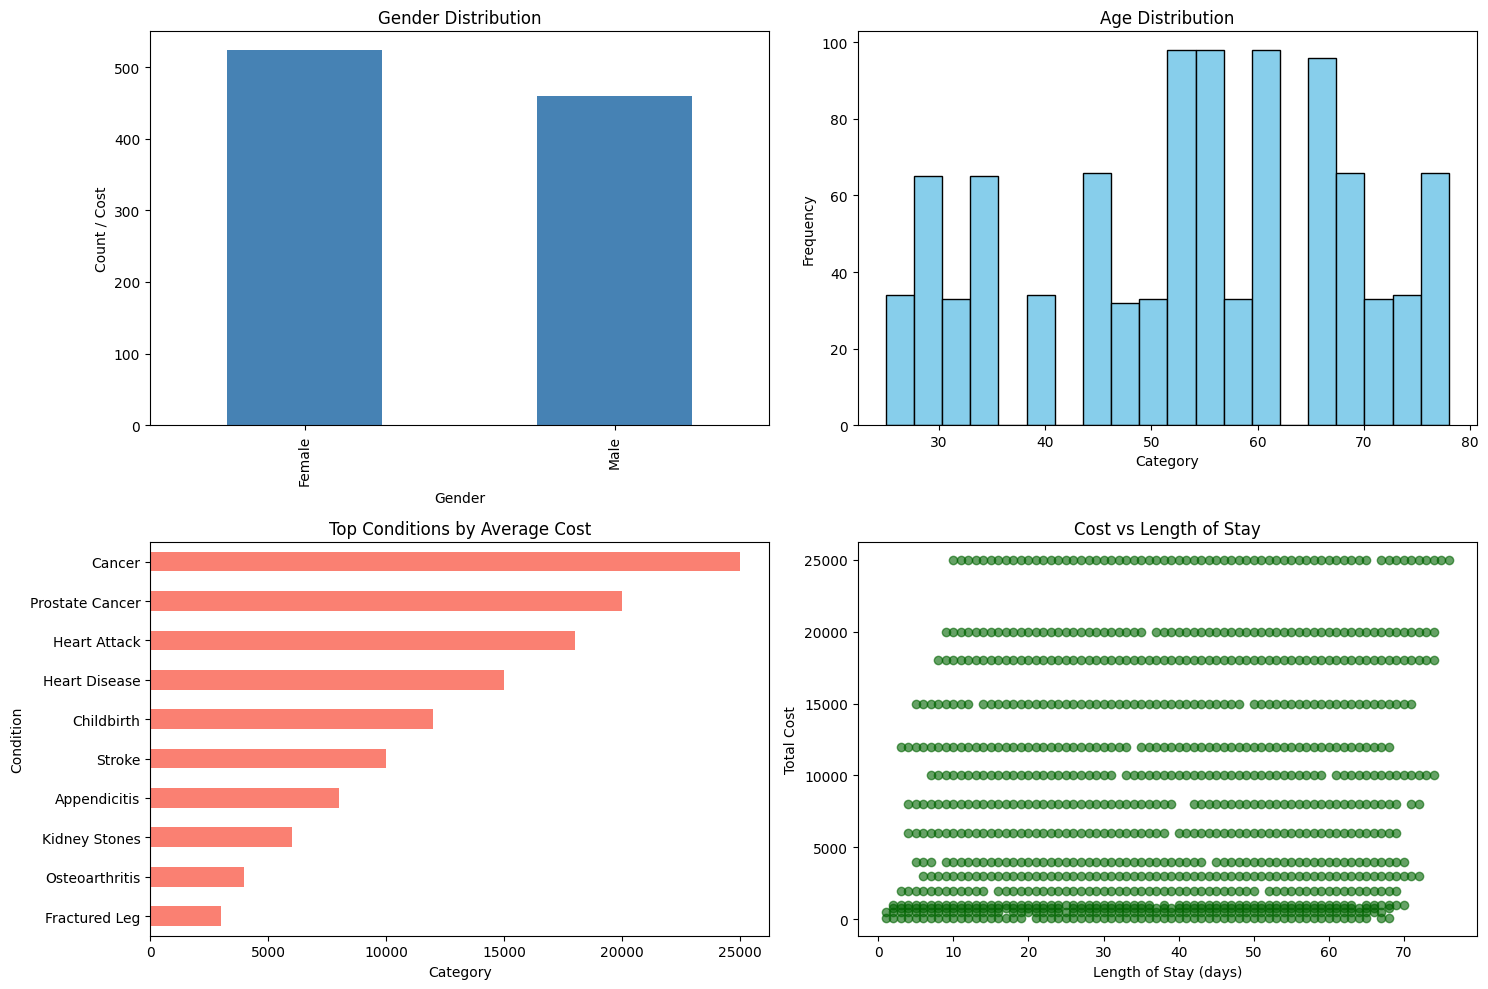

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
df['Gender'].value_counts().plot(kind='bar', ax=axes[0, 0], color='steelblue', title='Gender Distribution')
df['Age'].dropna().plot(kind='hist', bins=20, ax=axes[0, 1], color='skyblue', edgecolor='black', title='Age Distribution')
cost_by_condition.sort_values().plot(kind='barh', ax=axes[1, 0], color='salmon', title='Top Conditions by Average Cost')
axes[1, 1].scatter(df['Length_of_Stay'], df['Total_Cost'], alpha=0.6, color='darkgreen')
axes[1, 1].set(title='Cost vs Length of Stay', xlabel='Length of Stay (days)', ylabel='Total Cost')
for axis in axes.flat:
    axis.set_xlabel(axis.get_xlabel() or 'Category')
    axis.set_ylabel(axis.get_ylabel() or 'Count / Cost')
fig.tight_layout()
plt.show()
